# Mini Project: Random Forest Classification
##  Identifying Date Fruit Varieties

Group members: Shaden, Norah, Aljoharh, Sulaiman.

# 1. Introduction

In this project, we use Random Forest Classification to predict the variety of a date fruit based on its physical characteristics.

Dataset: Date Fruit Dataset, containing 898 dates, 34 numerical features, and 7 varieties: Sukkari, Safawi, Ruthana, Deglet, Sagai, Barni, and Barhi.

Goal: identify the most important features for distinguishing date varieties and build a model that accurately classifies them.

# 2. Algorithm Explanation

1- What is the algorithm?

Random Forest Classification is a machine learning algorithm that uses multiple decision trees to predict categories or classes. It combines the predictions of many trees and selects the class receiving the most votes as the final prediction.

For example, it can classify an object into categories such as different types of fruit, animals, or other classes.

2- How does the algorithm work?

Random Forest builds multiple decision trees using random samples of the training data and random subsets of features. Each tree independently predicts a class, and the final prediction is the class receiving the majority of votes from all trees.

Using multiple trees helps the model learn different patterns in the data and make more reliable predictions than relying on a single decision tree.

3- When should this algorithm be used?

- When the target variable consists of categories or classes rather than continuous numerical values.

- When the relationship between features and the target is complex or non-linear.

- When several features interact and jointly influence the predicted class.

- When the dataset contains a mixture of numerical and categorical features, provided categorical features are appropriately encoded.

- When we want a strong classification model without extensive preprocessing, since decision trees do not require feature scaling.

4- Advantages and Limitations

**Advantages**
- High accuracy: often performs well on complex classification problems.
- Reduced overfitting: combining multiple trees generally makes it less prone to overfitting than a single decision tree.
- Handles complex relationships: can learn non-linear patterns and interactions between features.
- Feature importance: helps identify which features contribute most to the model's predictions.
- No feature scaling needed: numerical features do not need to be standardized or normalized.

**Limitations**
- Hard to interpret: the combined decisions of many trees are more difficult to explain than a single decision tree.
- Higher computational cost: training and storing many trees requires more time and memory than using one tree.
- Requires categorical encoding: categorical features generally need to be converted into numerical representations when using scikit-learn's Random Forest implementation.
- Requires tuning: parameters such as n_estimators, max_depth, and min_samples_leaf may need adjustment to achieve the best performance.
- Can struggle with imbalanced classes: when some classes have significantly fewer samples than others, the model may favor the more frequent classes.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Setup and loading the data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

In [3]:
URL = "https://raw.githubusercontent.com/DataRohit/Date-Fruit-Classification/master/Date_Fruit_Datasets.xlsx"
df = pd.read_excel(URL)

names = {"DOKOL": "Sukkari", "SAFAVI": "Safawi", "ROTANA": "Ruthana", "DEGLET": "Deglet",
         "SOGAY": "Sagai", "IRAQI": "Barni", "BERHI": "Barhi"}
df["Variety"] = df["Class"].map(names)
df.head()

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class,Variety
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI,Barhi
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI,Barhi
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI,Barhi
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI,Barhi
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI,Barhi


### 3.2 Dataset structure

In [4]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.dtypes.value_counts()

Shape: (898, 36)
Missing values: 0
Duplicate rows: 0


float64    29
int64       5
object      2
dtype: int64

- **898 dates**, **34 numeric features**, and the target `Class` (7 varieties). We added a `Variety` column with the names our team uses.
- **No missing values and no duplicate rows.**
- The 34 features fall into **3 groups**, all measured from each date's photo:

| Group | Features | Meaning |
|---|---|---|
|  **Size** (6) | `AREA`, `PERIMETER`, `MAJOR_AXIS`, `MINOR_AXIS`, `EQDIASQ`, `CONVEX_AREA` | How big the date is: area, outline length, length, width |
|  **Shape** (10) | `ECCENTRICITY`, `SOLIDITY`, `EXTENT`, `ASPECT_RATIO`, `ROUNDNESS`, `COMPACTNESS`, `SHAPEFACTOR_1-4` | Long or round? Smooth or wrinkled edges? |
|  **Colour** (18) | `Mean`, `StdDev`, `Skew`, `Kurtosis`, `Entropy`, `ALLdaub4`, each for the R, G, B channels | Light or dark? Even or patchy colour? Surface texture |

In [5]:
size = ["AREA", "PERIMETER", "MAJOR_AXIS", "MINOR_AXIS", "EQDIASQ", "CONVEX_AREA"]
shape = ["ECCENTRICITY", "SOLIDITY", "EXTENT", "ASPECT_RATIO", "ROUNDNESS", "COMPACTNESS",
         "SHAPEFACTOR_1", "SHAPEFACTOR_2", "SHAPEFACTOR_3", "SHAPEFACTOR_4"]
features = [c for c in df.columns if c not in ("Class", "Variety")]
color = [c for c in features if c not in size + shape]
print(len(size), "size +", len(shape), "shape +", len(color), "color =", len(features), "features")

6 size + 10 shape + 18 color = 34 features


### 3.3 How many dates of each variety? (count plot)

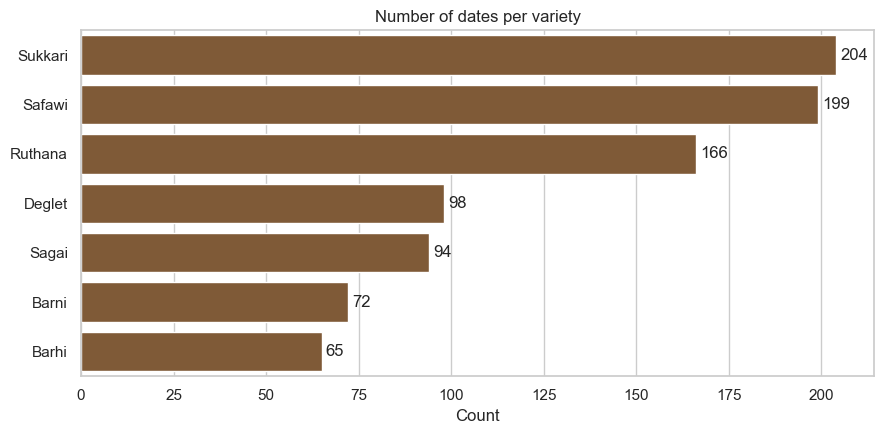

In [6]:
order = df["Variety"].value_counts().index
plt.figure(figsize=(9, 4.5))
ax = sns.countplot(data=df, y="Variety", order=order, color="#8B5A2B")
ax.bar_label(ax.containers[0], padding=3)
plt.title("Number of dates per variety"); plt.xlabel("Count"); plt.ylabel("")
plt.tight_layout(); plt.show()

**Interpretation:** the varieties are **not balanced**. Sukkari (204) and Safawi (199) have about three times as many dates as Barhi (65) and Barni (72). This is why we will:
- use a **stratified** train/test split, so every variety keeps the same share in both sets;
- look at **precision, recall and F1 for each variety**, not just overall accuracy.

### 3.4 Checking for outliers

In [7]:
df[["AREA", "MINOR_AXIS", "ASPECT_RATIO", "ROUNDNESS"]].describe().T[["min", "50%", "max"]]

,min,50%,max
AREA,1987.0000,319833.00000,546063.0000
MINOR_AXIS,2.2832,495.05485,766.4536
ASPECT_RATIO,1.0653,1.52415,535.5257
ROUNDNESS,0.0048,0.86775,0.9773


In [8]:
outliers = df[df["ASPECT_RATIO"] > 10]
outliers[["AREA", "MINOR_AXIS", "ASPECT_RATIO", "ROUNDNESS", "Variety"]]

,AREA,MINOR_AXIS,ASPECT_RATIO,ROUNDNESS,Variety
615,1987,2.2832,535.5257,0.0048,Safawi


**Interpretation:** one Safawi date has impossible values: an area of **1,987** pixels (the median is about 320,000), a width of **2.3** pixels, and an aspect ratio of **535** (a normal date is 1 to 2.3). This is almost certainly an **image-processing error**, not a real date, so we remove it in preprocessing.

### 3.5 Does size separate the varieties? (box plot)

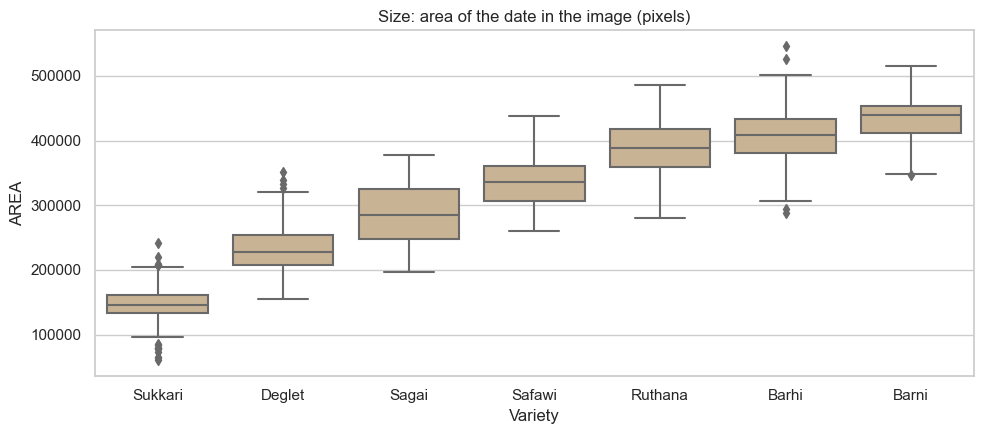

In [9]:
clean = df[df["ASPECT_RATIO"] <= 10]   # exclude the outlier for readable plots
order_area = clean.groupby("Variety")["AREA"].median().sort_values().index
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=clean, x="Variety", y="AREA", order=order_area, color="#D2B48C")
plt.title("Size: area of the date in the image (pixels)")
plt.tight_layout(); plt.show()

**Interpretation:** size clearly separates some varieties. **Sukkari is by far the smallest** (median area about 146,000 pixels), while **Barhi, Ruthana and Barni are the largest**. But the middle varieties (Deglet, Sagai, Safawi) overlap, so size alone is not enough.

### 3.6 Does shape separate the varieties? (box plot)

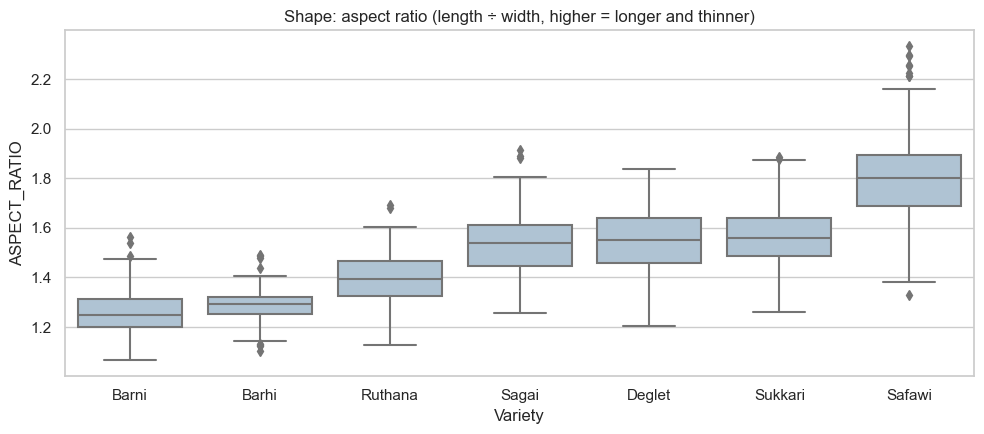

In [10]:
order_ar = clean.groupby("Variety")["ASPECT_RATIO"].median().sort_values().index
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=clean, x="Variety", y="ASPECT_RATIO", order=order_ar, color="#A9C4D9")
plt.title("Shape: aspect ratio (length ÷ width, higher = longer and thinner)")
plt.tight_layout(); plt.show()

**Interpretation:** **Safawi is the longest and thinnest** variety (median aspect ratio about 1.8), while **Barni and Barhi are the roundest** (about 1.25 to 1.3). Shape helps, but several varieties (Sagai, Deglet, Sukkari) have almost the same shape.

### 3.7 Does colour separate the varieties? (box plot)

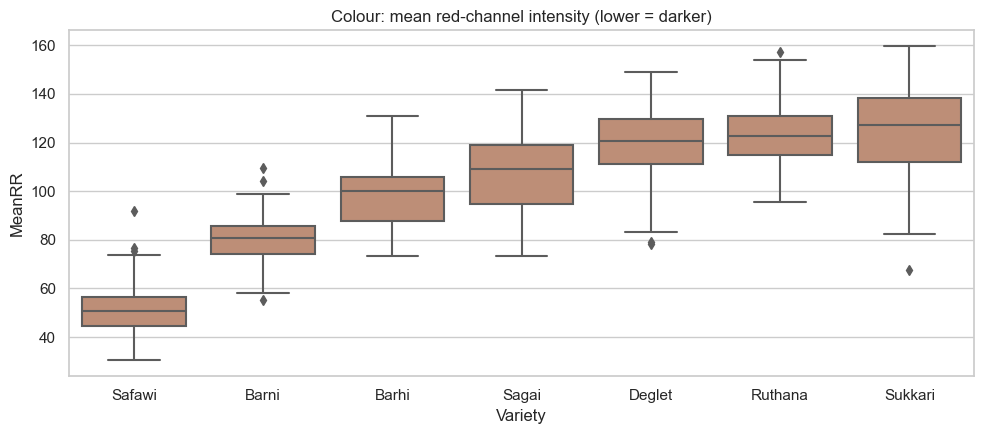

In [11]:
order_c = clean.groupby("Variety")["MeanRR"].median().sort_values().index
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=clean, x="Variety", y="MeanRR", order=order_c, color="#C98A6B")
plt.title("Colour: mean red-channel intensity (lower = darker)")
plt.tight_layout(); plt.show()

**Interpretation:** colour gives the clearest single signal. **Safawi is much darker than every other variety** (median red intensity about 51, while the others range from about 81 to 127), so it is easy to recognize. **Barni** is the next darkest. **Sukkari, Ruthana and Deglet are the lightest** and overlap with each other.

### 3.8 Combining size and colour (scatter plot)

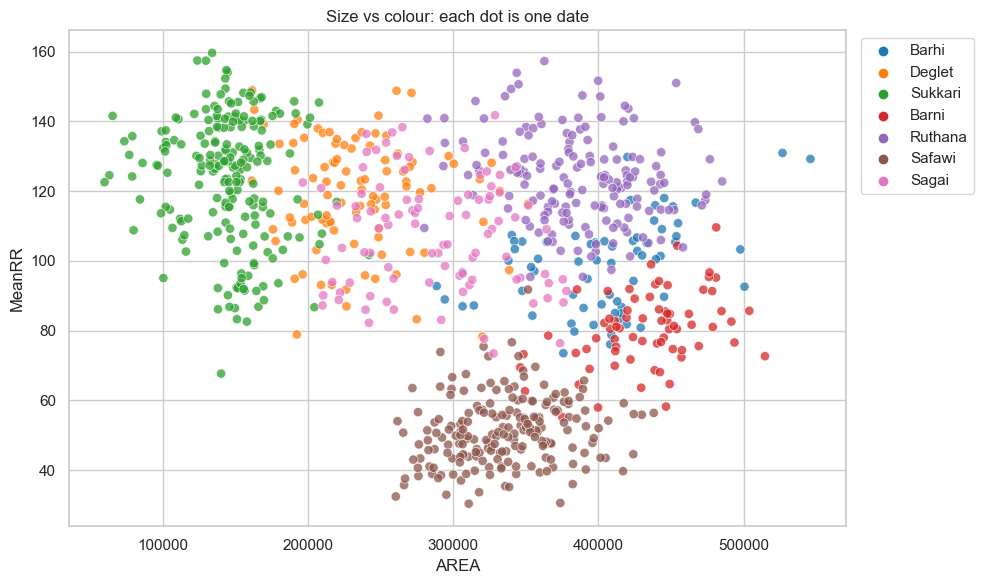

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean, x="AREA", y="MeanRR", hue="Variety", palette="tab10", alpha=.75, s=45)
plt.title("Size vs colour: each dot is one date")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Interpretation:** combining **size and colour** already separates the varieties into visible groups: **Sukkari** sits on the left (small and light), **Safawi** at the bottom (dark), **Barni** on the right (large and fairly dark), and **Ruthana** at the top right (large and light). Some varieties still overlap (for example Deglet and Sagai), which is why the model needs all features together.

### 3.9 Correlation heatmap

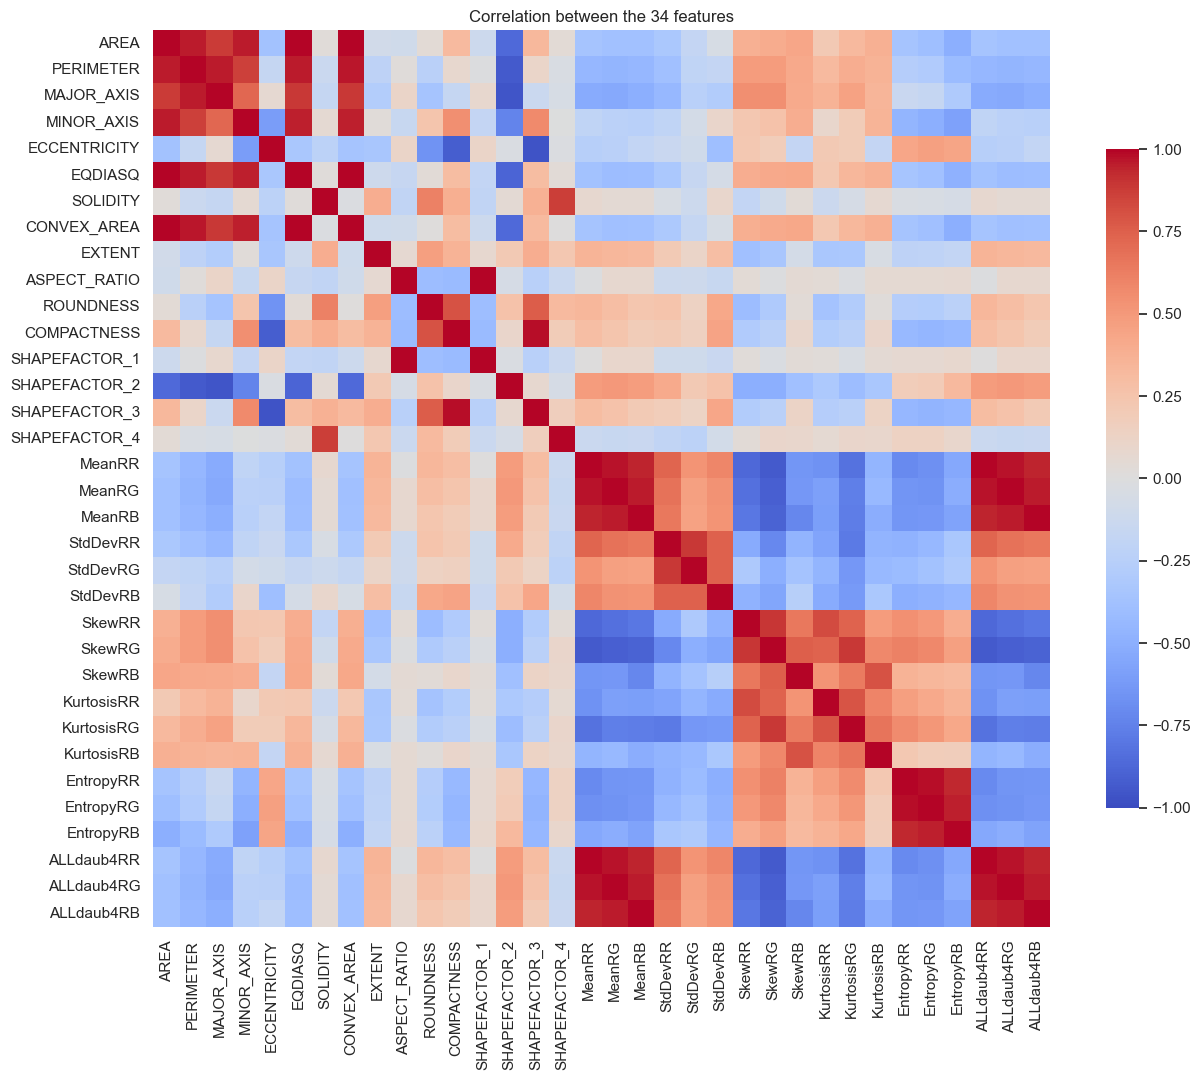

In [13]:
plt.figure(figsize=(13, 11))
sns.heatmap(df[features].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": .7})
plt.title("Correlation between the 34 features")
plt.tight_layout(); plt.show()

In [14]:
corr = df[features].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Feature pairs with |correlation| > 0.9:", (pairs > 0.9).sum())
pairs.sort_values(ascending=False).head(8).round(3)

Feature pairs with |correlation| > 0.9: 38


MeanRG        ALLdaub4RG       1.000
MeanRR        ALLdaub4RR       1.000
MeanRB        ALLdaub4RB       1.000
ASPECT_RATIO  SHAPEFACTOR_1    1.000
AREA          CONVEX_AREA      0.999
EQDIASQ       CONVEX_AREA      0.993
AREA          EQDIASQ          0.993
EntropyRR     EntropyRG        0.981
dtype: float64

**Interpretation:** many features are **strongly correlated**: 38 pairs have a correlation above 0.9. Some are essentially duplicates, e.g. `MeanRR` and `ALLdaub4RR` (1.000), or `AREA` and `CONVEX_AREA` (0.999). This makes sense: a date with a large area also has a large perimeter.

Random Forest copes well with redundant features (it still predicts well), but the redundancy means **importance gets shared between correlated features**, which we keep in mind when reading feature importance.

### EDA summary
- **Size** separates small varieties (Sukkari) from large ones (Barhi, Ruthana, Barni).
- **Shape** separates long varieties (Safawi) from round ones (Barni, Barhi).
- **Colour** separates dark varieties (Safawi, Barni) from light ones.
- **No single feature is enough on its own.** We need a model that combines all of them, which is exactly what Random Forest does.

## 4. Data Preprocessing

| Step | Decision | Reason |
|---|---|---|
| Missing values | Nothing to fill | No missing values were found |
| Duplicates | Nothing to remove | No duplicate rows |
| Outliers | **Remove 1 row** | One Safawi date has impossible measurements (likely an image-processing error) |
| Encoding | **Label-encode the target** | `Class` is text; the 34 features are already numeric |
| Scaling | **Not applied** for Random Forest | Trees split on thresholds, so the scale of a feature doesn't matter |
| Split | 80% train / 20% test, **stratified** | Keeps the same share of each variety in both sets, since the classes are imbalanced |

In [15]:
data = df[df["ASPECT_RATIO"] <= 10].reset_index(drop=True)
print("Rows after removing the outlier:", len(data))

le = LabelEncoder()
y = le.fit_transform(data["Variety"])
X = data[features]
print(dict(zip(le.classes_, le.transform(le.classes_))))

Rows after removing the outlier: 897
{'Barhi': 0, 'Barni': 1, 'Deglet': 2, 'Ruthana': 3, 'Safawi': 4, 'Sagai': 5, 'Sukkari': 6}


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (717, 34)  Test: (180, 34)


## 5. Model Training

### 5.1 Training the Random Forest
We start with a forest of **100 trees** and scikit-learn's default settings. `random_state` makes the results reproducible.

In [17]:
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

## 6. Model Evaluation

### 6.1 Overall metrics
Because the varieties are imbalanced, we use **macro averages**: each variety counts equally, so small varieties like Barhi matter as much as large ones like Sukkari.

In [18]:
metrics = pd.DataFrame({"Score": [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, average="macro"),
    recall_score(y_test, y_pred, average="macro"),
    f1_score(y_test, y_pred, average="macro"),
]}, index=["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"])
metrics.round(3)

,Score
Accuracy,0.950
Precision (macro),0.947
Recall (macro),0.939
F1-score (macro),0.942


**Interpretation:**
- **Accuracy 95.0%**: 171 of 180 test dates were classified correctly.
- **Precision 94.7%**: when the model names a variety, it is right about 95% of the time.
- **Recall 93.9%**: on average, the model finds about 94% of the dates of each variety.
- **F1-score 94.2%**: precision and recall are balanced, so the model is not favouring the large varieties.

### 6.2 Results for each variety

In [28]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

       Barhi       1.00      0.92      0.96        13
       Barni       0.93      0.93      0.93        14
      Deglet       0.78      0.90      0.84        20
     Ruthana       0.97      1.00      0.99        33
      Safawi       1.00      1.00      1.00        40
       Sagai       1.00      0.89      0.94        19
     Sukkari       0.95      0.93      0.94        41

    accuracy                           0.95       180
   macro avg       0.95      0.94      0.94       180
weighted avg       0.95      0.95      0.95       180



**Interpretation:** **Safawi** was classified perfectly (F1 = 1.00) and **Ruthana** almost perfectly (0.99). The weakest variety is **Deglet** (F1 = 0.84), followed by Barni, Sagai and Sukkari (0.93 to 0.94). These light-coloured varieties look alike, so the model sometimes confuses them.

### 6.3 Confusion matrix
Rows are the true variety and columns are the predicted one. The diagonal shows correct predictions; everything else is a mistake.

In [19]:
print(confusion_matrix(y_test, y_pred))


[[12  1  0  0  0  0  0]
 [ 0 13  0  1  0  0  0]
 [ 0  0 18  0  0  0  2]
 [ 0  0  0 33  0  0  0]
 [ 0  0  0  0 40  0  0]
 [ 0  0  2  0  0 17  0]
 [ 0  0  3  0  0  0 38]]


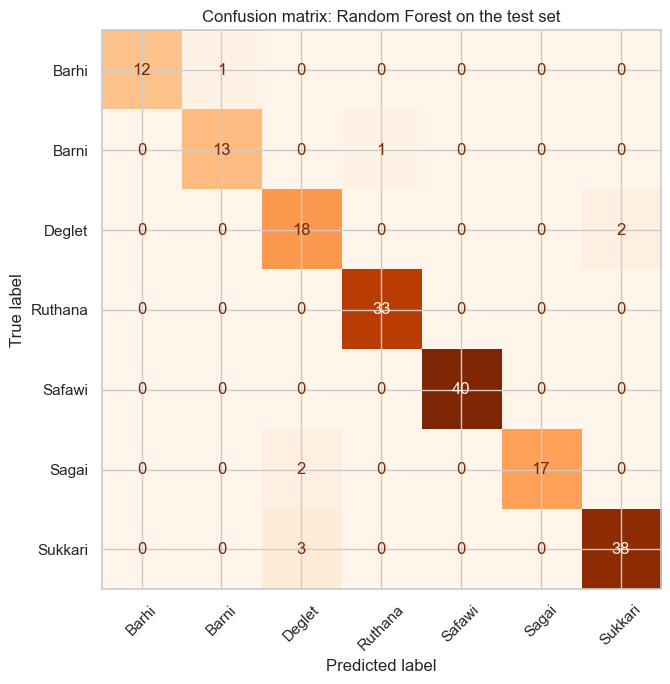

In [20]:
#Display the Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_,
                                        cmap="Oranges", colorbar=False, ax=ax)
plt.title("Confusion matrix: Random Forest on the test set")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

**Interpretation:** the model made only **9 mistakes**, and most of them are between **Deglet, Sukkari and Sagai**:
- 3 Sukkari → predicted Deglet, and 2 Deglet → predicted Sukkari
- 2 Sagai → predicted Deglet

This matches the EDA: these three varieties are **light-coloured and have similar shapes**, so they overlap in almost every feature. The dark varieties (Safawi, Barni) and the large ones (Ruthana, Barhi) are almost never confused.

### 6.4 Feature importance
Which measurements did the forest rely on most? We show the top 10 features, then add up the importance of each group (size, shape, colour).

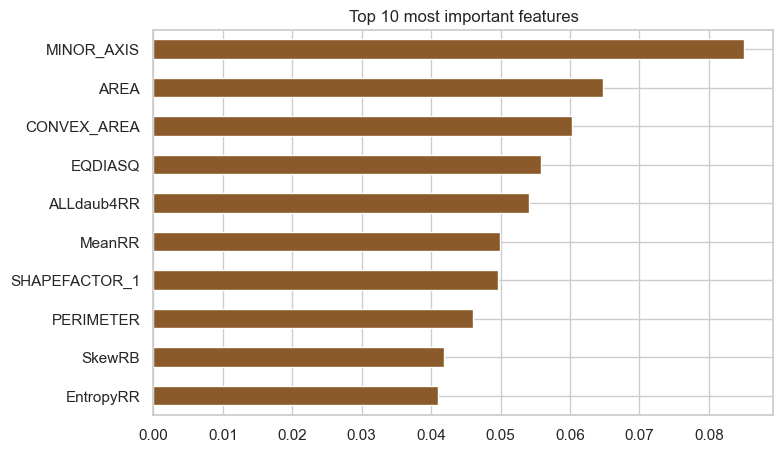

Colour    0.492
Shape     0.178
Size      0.331
dtype: float64

In [21]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
imp.head(10)[::-1].plot.barh(figsize=(8, 5), color="#8B5A2B")
plt.title("Top 10 most important features")
plt.show()

group = {f: "Size" for f in size} | {f: "Shape" for f in shape} | {f: "Colour" for f in color}
imp.groupby(imp.index.map(group)).sum().round(3)

**Interpretation:** the single most important feature is the date's width (`MINOR_AXIS`), but when we add up each group, **colour carries about half of the importance (49%)**, size 33% and shape 18%.

## ⭐ Bonus: Comparison and Tuning
We tried three things: (1) cross-validation of our Random Forest, (2) comparing it with **Logistic Regression**, and (3) tuning the forest with **GridSearchCV**. All scores use macro F1 with 5-fold stratified cross-validation on the training set.

In [22]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_cv = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("F1 for each fold:", rf_cv)
print("Average F1:", rf_cv.mean())

F1 for each fold: [0.90972628 0.87926952 0.78528879 0.8671917  0.80485713]
Average F1: 0.8492666820809186


In [23]:
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    )
)

lr_cv = cross_val_score(
    lr,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("F1 for each fold:", lr_cv)
print("Average F1:", lr_cv.mean())

F1 for each fold: [0.91909383 0.90024339 0.85594519 0.89538137 0.91770624]
Average F1: 0.8976740014282327


In [25]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 0.5]
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE
    ),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_rf = grid.best_estimator_

print("Best parameters:", grid.best_params_)
print("Best average F1:", grid.best_score_)

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Best average F1: 0.8492666820809186


In [26]:
comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Logistic Regression",
        "Tuned Random Forest"
    ],
    "CV F1 macro": [
        rf_cv.mean(),
        lr_cv.mean(),
        grid.best_score_
    ]
})

comparison = comparison.sort_values(
    "CV F1 macro",
    ascending=False
).reset_index(drop=True)

comparison.round(4)

,Model,CV F1 macro
0,Logistic Regression,0.8977
1,Original Random Forest,0.8493
2,Tuned Random Forest,0.8493


In [27]:
models = {
    "Original Random Forest": rf,
    "Logistic Regression": lr,
    "Tuned Random Forest": best_rf
}

selected_name = comparison.loc[0, "Model"]
selected_model = models[selected_name]

selected_model.fit(X_train, y_train)
bonus_pred = selected_model.predict(X_test)

print("Selected model:", selected_name)

test_comparison = pd.DataFrame({
    "Model": ["Original Random Forest", selected_name],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, bonus_pred)
    ],
    "Test F1 macro": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, bonus_pred, average="macro")
    ]
})

print(test_comparison.round(4).to_string(index=False))

print("\nClassification Report:")
print(classification_report(
    y_test,
    bonus_pred,
    target_names=le.classes_,
    zero_division=0
))

Selected model: Logistic Regression
                 Model  Test Accuracy  Test F1 macro
Original Random Forest         0.9500         0.9419
   Logistic Regression         0.9444         0.9299

Classification Report:
              precision    recall  f1-score   support

       Barhi       0.92      0.92      0.92        13
       Barni       0.93      0.93      0.93        14
      Deglet       0.84      0.80      0.82        20
     Ruthana       0.97      0.97      0.97        33
      Safawi       1.00      1.00      1.00        40
       Sagai       1.00      0.84      0.91        19
     Sukkari       0.91      1.00      0.95        41

    accuracy                           0.94       180
   macro avg       0.94      0.92      0.93       180
weighted avg       0.95      0.94      0.94       180



## 7. Conclusion

- Random Forest identified the variety of **95% of the test dates** (171 of 180), with a macro F1-score of **94.2%**, using only measurements taken from each date's photo.
- **Colour is the most important group of features** (about 49% of the importance), followed by size (33%) and shape (18%). Safawi is the easiest variety to recognise because it is much darker than the others.
- Most mistakes happened between **Sukkari, Deglet and Sagai**, which are light-coloured and similar in shape, exactly as the EDA showed.
- In the bonus, Logistic Regression scored slightly higher in cross-validation (F1 0.898 vs 0.849), and tuning did not change the forest's settings, so Random Forest already works well with its defaults.
- **Practical use:** a camera on a factory sorting line could use a model like this to sort dates by variety automatically.